In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv('netflix_customer_churn.csv')

print(df.head())

                            customer_id  age  gender subscription_type  \
0  a9b75100-82a8-427a-a208-72f24052884a   51   Other             Basic   
1  49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b   47   Other          Standard   
2  4d71f6ce-fca9-4ff7-8afa-197ac24de14b   27  Female          Standard   
3  d3c72c38-631b-4f9e-8a0e-de103cad1a7d   53   Other           Premium   
4  4e265c34-103a-4dbb-9553-76c9aa47e946   56   Other          Standard   

   watch_hours  last_login_days   region  device  monthly_fee  churned  \
0        14.73               29   Africa      TV         8.99        1   
1         0.70               19   Europe  Mobile        13.99        1   
2        16.32               10     Asia      TV        13.99        0   
3         4.51               12  Oceania      TV        17.99        1   
4         1.89               13   Africa  Mobile        13.99        1   

  payment_method  number_of_profiles  avg_watch_time_per_day favorite_genre  
0      Gift Card                

In [3]:
display(df.head())
print(df.info())

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 547.0

In [4]:
#checking customer_id is unique
Customer_id1=df['customer_id'].unique()
print(len(Customer_id1))

5000


gender,Male
subscription_type,
Standard,581
Premium,568
Basic,505


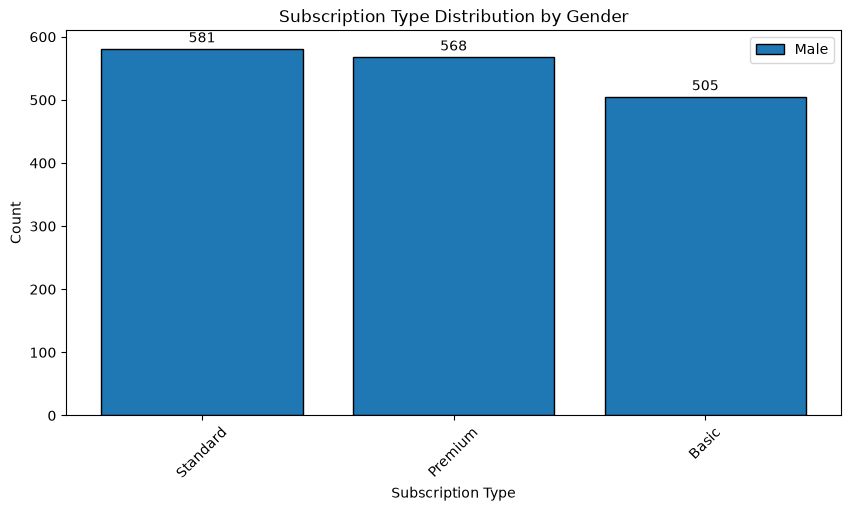

In [5]:
#subscription type Based gender
Subscription_type_gender=df[df['gender']=='Male'].groupby(['subscription_type','gender']).size().unstack()
Subscription_type_gender=Subscription_type_gender.sort_values(by='Male',ascending=False)

display(Subscription_type_gender)
plt.figure(figsize=(10,5))
bars=plt.bar(Subscription_type_gender.index, Subscription_type_gender['Male'],edgecolor='black',label='Male')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, int(yval), ha='center', va='bottom')



plt.xlabel('Subscription Type')
plt.ylabel('Count')
plt.title('Subscription Type Distribution by Gender')
plt.xticks(rotation=45)
plt.legend()
plt.show()

gender,Female
subscription_type,
Basic,606
Standard,554
Premium,551


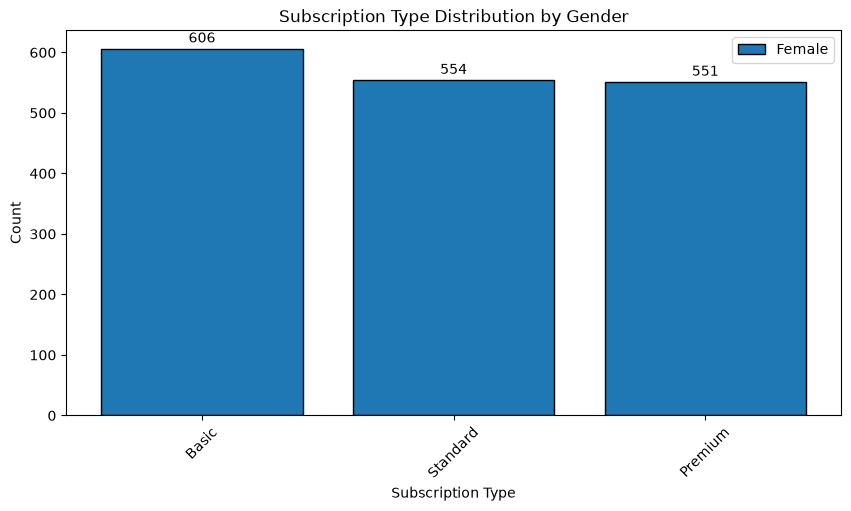

In [6]:
#subscription type Based gender
Subscription_type_gender_F=df[df['gender']=='Female'].groupby(['subscription_type','gender']).size().unstack()
Subscription_type_gender_F=Subscription_type_gender_F.sort_values(by='Female',ascending=False)

display(Subscription_type_gender_F)
plt.figure(figsize=(10,5))
bars=plt.bar(Subscription_type_gender_F.index, Subscription_type_gender_F['Female'],edgecolor='black',label='Female')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, int(yval), ha='center', va='bottom')



plt.xlabel('Subscription Type')
plt.ylabel('Count')
plt.title('Subscription Type Distribution by Gender')
plt.xticks(rotation=45)
plt.legend()
plt.show()

gender,Other
subscription_type,
Premium,574
Basic,550
Standard,511


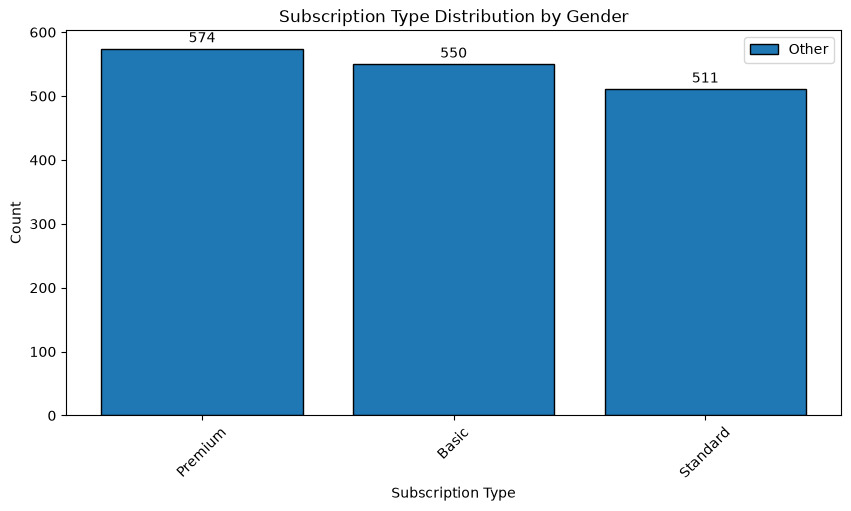

In [7]:
#subscription type Based gender
Subscription_type_gender_o=df[df['gender']=='Other'].groupby(['subscription_type','gender']).size().unstack()
Subscription_type_gender_o=Subscription_type_gender_o.sort_values(by='Other',ascending=False)

display(Subscription_type_gender_o)
plt.figure(figsize=(10,5))
bars=plt.bar(Subscription_type_gender_o.index, Subscription_type_gender_o['Other'],edgecolor='black',label='Other')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, int(yval), ha='center', va='bottom')



plt.xlabel('Subscription Type')
plt.ylabel('Count')
plt.title('Subscription Type Distribution by Gender')
plt.xticks(rotation=45)
plt.legend()
plt.show()

In [8]:
average_watch_time_by_gender = df.groupby('gender')['watch_hours'].mean().sort_values(ascending=False)
display(average_watch_time_by_gender)

gender
Other     11.770856
Male      11.618259
Female    11.563589
Name: watch_hours, dtype: float64

subscription_type,Basic,Premium,Standard
gender,,,
Male,505,568,581
Female,606,551,554
Other,550,574,511


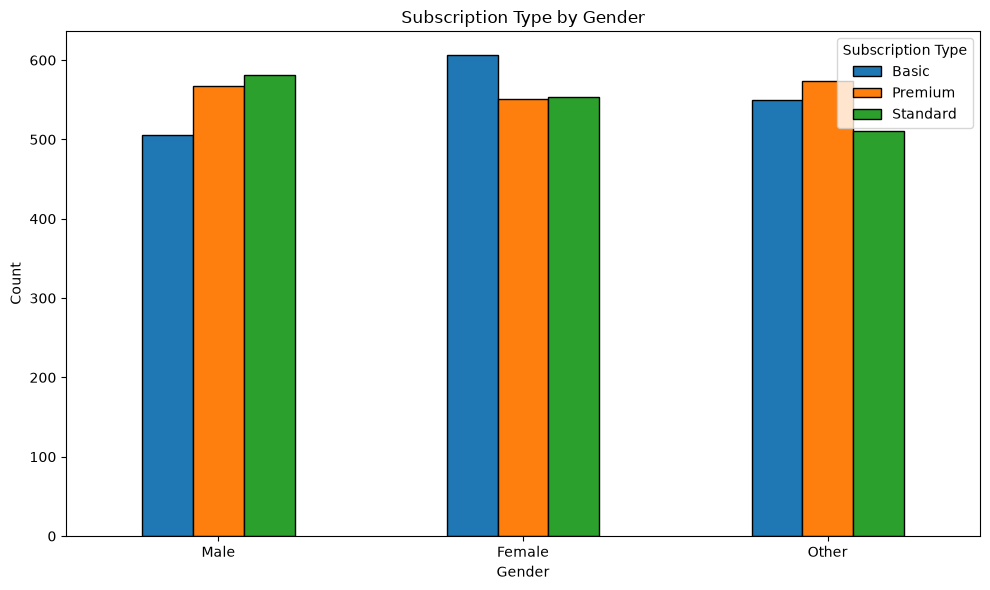

In [9]:
# Gender-wise subscription type distribution
gender_subscription = pd.crosstab(df['gender'], df['subscription_type']).reindex(index=['Male', 'Female', 'Other'], fill_value=0)
display(gender_subscription)

gender_subscription.plot(
    kind='bar',
    figsize=(10, 6),
    edgecolor='black',
    title='Subscription Type by Gender'
)
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='Subscription Type')
plt.tight_layout()
plt.show()

,AgeGroup,watch_hours
1,26–39,11.844389
2,40+,11.747369
0,18–25,10.974682


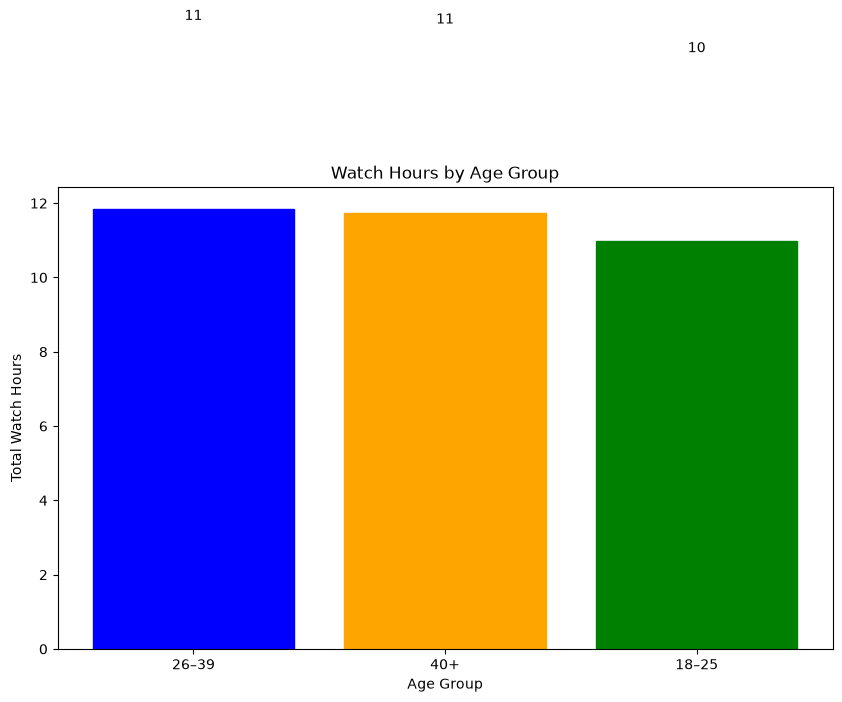

In [10]:
age_bins = [17, 25, 39, float("inf")]
age_labels = ["18–25", "26–39", "40+"]

df["AgeGroup"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels,
    right=True
)
age_sales = (
    df.groupby("AgeGroup", observed=False)["watch_hours"]
      .mean()
      .reindex(age_labels)
      .reset_index().sort_values(by='watch_hours',ascending=False)
)

display(age_sales)
plt.figure(figsize=(10, 6))
bars = plt.bar(age_sales["AgeGroup"], age_sales["watch_hours"], edgecolor='black')
bars[0].set_color('blue'), bars[1].set_color('orange'), bars[2].set_color('green')
for bar in bars:    
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, int(yval), ha='center', va='bottom')    

plt.xlabel('Age Group')
plt.ylabel('Total Watch Hours')
plt.title('Watch Hours by Age Group')
plt.show()


AgeGroup
18–25     77.90
26–39     79.17
40+      110.40
Name: watch_hours, dtype: float64

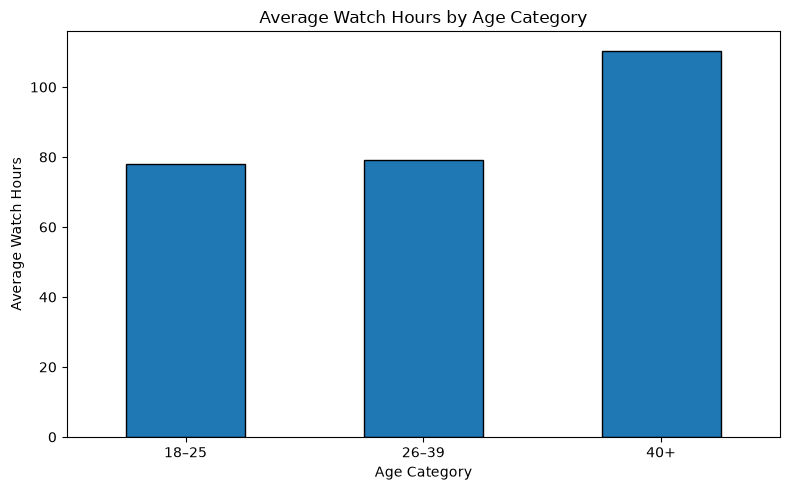

In [11]:
average_watch_hours_by_age = (
    df.groupby("AgeGroup", observed=False)["watch_hours"]
      .max()
      .reindex(age_labels)
)

display(average_watch_hours_by_age)

ax = average_watch_hours_by_age.plot(
    kind="bar",
    figsize=(8, 5),
    edgecolor="black",
    title="Average Watch Hours by Age Category"
)
ax.set_xlabel("Age Category")
ax.set_ylabel("Average Watch Hours")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,watch_hours
gender,
Other,11.770856
Male,11.618259
Female,11.563589


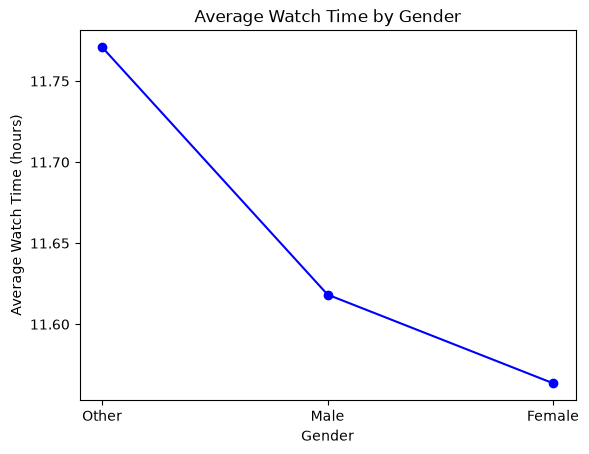

In [12]:
Average_watch_time_by_gender=df[['gender','watch_hours']].groupby('gender').mean().sort_values(by='watch_hours',ascending=False)
display(Average_watch_time_by_gender)
plt.Figure(figsize=(10,5))
plots=plt.plot(Average_watch_time_by_gender.index,Average_watch_time_by_gender['watch_hours'],marker='o',linestyle='-',color='b')
plt.title('Average Watch Time by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Watch Time (hours)')
plt.show()

In [13]:
#favorite genre based on age group
favorite_genre_by_age_group = df.groupby('AgeGroup')['favorite_genre'].agg(lambda x: x.mode()[0] if not x.mode().empty else np.nan)
display(favorite_genre_by_age_group)

AgeGroup
18–25         Sci-Fi
26–39          Drama
40+      Documentary
Name: favorite_genre, dtype: str

In [14]:
#favorite genre based on gender
favorite_genre_by_gender = df.groupby('gender')['favorite_genre'].agg(lambda x: x.mode()[0] if not x.mode().empty else np.nan)
display(favorite_genre_by_gender)

gender
Female     Sci-Fi
Male        Drama
Other     Romance
Name: favorite_genre, dtype: str

In [15]:
#favorite genre based on subscription type
favorite_genre_by_subscription_type = df.groupby('subscription_type')['favorite_genre'].agg(lambda x: x.mode()[0] if not x.mode().empty else np.nan)
display(favorite_genre_by_subscription_type)

subscription_type
Basic       Romance
Premium       Drama
Standard     Sci-Fi
Name: favorite_genre, dtype: str

In [16]:
#favorite genre based on region
favorite_genre_by_region = df.groupby('region')['favorite_genre'].agg(lambda x: x.mode()[0] if not x.mode().empty else np.nan)
display(favorite_genre_by_region)

region
Africa           Documentary
Asia                  Horror
Europe                Sci-Fi
North America         Action
Oceania                Drama
South America          Drama
Name: favorite_genre, dtype: str

In [17]:
#age based subscription type distribution
age_subscription_distribution = pd.crosstab(df['AgeGroup'], df['subscription_type']).reindex(index=age_labels, fill_value=0)
display(age_subscription_distribution)

subscription_type,Basic,Premium,Standard
AgeGroup,,,
18–25,256,281,264
26–39,425,452,456
40+,980,960,926


In [18]:
#age based payment method distribution
age_payment_distribution = pd.crosstab(df['AgeGroup'], df['payment_method']).reindex(index=age_labels, fill_value=0)
display(age_payment_distribution)

payment_method,Credit Card,Crypto,Debit Card,Gift Card,PayPal
AgeGroup,,,,,
18–25,152,150,177,151,171
26–39,263,263,269,269,269
40+,558,582,584,556,586


In [19]:
#monthly revenue based on subscription type
monthly_revenue_by_subscription_type = df.groupby('subscription_type')['monthly_fee'].sum().sort_values(ascending=False)
display(monthly_revenue_by_subscription_type)

subscription_type
Premium     30457.07
Standard    23027.54
Basic       14932.39
Name: monthly_fee, dtype: float64

In [20]:
#age based monthly revenue distribution
age_monthly_revenue_distribution = df.groupby('AgeGroup')['monthly_fee'].sum().reindex(index=age_labels, fill_value=0)
display(age_monthly_revenue_distribution)


AgeGroup
18–25    11049.99
26–39    18331.67
40+      39035.34
Name: monthly_fee, dtype: float64

In [21]:
#age based churn distribution
age_churn_distribution = pd.crosstab(df['AgeGroup'], df['churned']).reindex(index=age_labels, fill_value=0)
display(age_churn_distribution)

churned,0,1
AgeGroup,,
18–25,395,406
26–39,675,658
40+,1415,1451


In [22]:
#subscription based churn distribution
subscription_churn_distribution = pd.crosstab(df['subscription_type'], df['churned']).sort_values(by=1, ascending=False)
display(subscription_churn_distribution)

churned,0,1
subscription_type,,
Basic,634,1027
Standard,898,748
Premium,953,740


In [23]:
#leading subscription type by age group
leading_subscription_by_age_group = df.groupby('AgeGroup')['subscription_type'].agg(lambda x: x.mode()[0] if not x.mode().empty else np.nan).reindex(age_labels)
display(leading_subscription_by_age_group)

AgeGroup
18–25     Premium
26–39    Standard
40+         Basic
Name: subscription_type, dtype: str

In [24]:
churn_customers = df.loc[(df["last_login_days"] > 10) & (df["watch_hours"] < 5)].copy()

print(f"Churn-risk customers: {len(churn_customers)}")
display(churn_customers)

Churn-risk customers: 1439


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,AgeGroup
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi,40+
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror,40+
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action,40+
9,eae6439e-8cdf-4258-ab49-c493925b927a,32,Other,Premium,2.22,34,Europe,TV,17.99,1,Debit Card,1,0.06,Drama,26–39
16,bf48551e-a8e6-4fd9-bb32-3f798ed84680,46,Other,Premium,1.25,13,Europe,Tablet,17.99,1,Debit Card,3,0.09,Comedy,40+
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4980,5a416884-375a-4442-b7c6-b480321dd6fd,57,Male,Standard,3.64,36,South America,Laptop,13.99,1,Crypto,5,0.10,Comedy,40+
4981,b35d25da-2139-4003-95ae-4692112104fc,20,Other,Standard,0.75,53,Asia,Tablet,13.99,1,PayPal,3,0.01,Action,18–25
4990,edb9036d-95f9-4998-9910-78ba85869dbd,57,Male,Standard,2.09,13,Asia,TV,13.99,1,Crypto,3,0.15,Romance,40+
4993,f915a366-31c7-4a9e-9042-ca526c771219,23,Other,Standard,3.10,12,Europe,Laptop,13.99,1,Crypto,5,0.24,Comedy,18–25


In [25]:
churn_customers = df.loc[df["churned"] == 1].copy()

print(f"Churn-risk customers: {len(churn_customers)}")
display(churn_customers)

Churn-risk customers: 2515


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,AgeGroup
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action,40+
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi,40+
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror,40+
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action,40+
7,02387681-8c42-462a-807a-de0168c73b38,51,Male,Basic,14.30,56,Europe,Mobile,8.99,1,Gift Card,1,0.25,Action,40+
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4990,edb9036d-95f9-4998-9910-78ba85869dbd,57,Male,Standard,2.09,13,Asia,TV,13.99,1,Crypto,3,0.15,Romance,40+
4992,9721209e-3147-456f-a2c0-81d23b4cf822,34,Male,Standard,10.25,41,Oceania,Desktop,13.99,1,Crypto,3,0.24,Documentary,26–39
4993,f915a366-31c7-4a9e-9042-ca526c771219,23,Other,Standard,3.10,12,Europe,Laptop,13.99,1,Crypto,5,0.24,Comedy,18–25
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action,40+


In [26]:
churn_customers = df.loc[df["churned"] == 0].copy()

print(f"Churn-risk customers: {len(churn_customers)}")
display(churn_customers)

Churn-risk customers: 2485


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,AgeGroup
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama,26–39
5,d8079475-5be7-47e9-8782-ceb7ff61395e,58,Female,Standard,13.80,26,Oceania,Mobile,13.99,0,Debit Card,3,0.51,Action,40+
6,8e63450a-13d6-4e83-bbb5-6aebde9152cb,48,Other,Basic,13.83,20,Asia,TV,8.99,0,Gift Card,5,0.66,Romance,40+
8,0bcaad0c-545c-4ee1-85a6-75e165f39361,45,Other,Basic,9.98,10,Asia,Mobile,8.99,0,PayPal,3,0.91,Romance,40+
10,45a03ce3-26d0-4cd5-a9bd-22d42490b612,26,Male,Premium,15.42,36,Asia,Laptop,17.99,0,Debit Card,4,0.42,Comedy,26–39
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4991,ac6eb271-0239-4957-b828-c89508fcfbea,62,Male,Standard,7.31,26,Oceania,Desktop,13.99,0,Credit Card,2,0.27,Sci-Fi,40+
4994,75532a22-9cd9-492c-8865-fa4ac7da2ec8,58,Other,Basic,10.90,22,Europe,TV,8.99,0,Credit Card,3,0.47,Action,40+
4995,44f3ba44-b95d-4e50-a786-bac4d06f4a43,19,Female,Basic,49.17,11,Europe,Desktop,8.99,0,Credit Card,4,4.10,Drama,18–25
4996,18779bcb-ba2b-41da-b751-e70b812061ec,67,Female,Basic,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary,40+


In [27]:
devices=df.groupby('region')['device'].agg(lambda x: x.mode()[0] if not x.mode().empty else np.nan)
display(devices)

region
Africa           Laptop
Asia                 TV
Europe           Mobile
North America    Tablet
Oceania          Tablet
South America    Laptop
Name: device, dtype: str

In [28]:
payment_type=df.groupby('region')['payment_method'].agg(lambda x: x.mode()[0] if not x.mode().empty else np. nan)
display(payment_type)


region
Africa                PayPal
Asia                  PayPal
Europe           Credit Card
North America     Debit Card
Oceania           Debit Card
South America         Crypto
Name: payment_method, dtype: str

,region,count
0,South America,873
1,Europe,867
2,North America,851
3,Asia,841
4,Africa,803
5,Oceania,765


<function matplotlib.pyplot.show(close=None, block=None)>

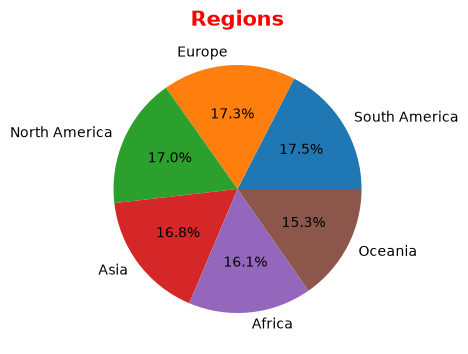

In [29]:
region=df['region'].value_counts().reset_index()
#total_count=region.sum()
#average=(region['count']/total_count)*100
display(region)
#print(average)
plt.figure(figsize=(4,9))
plt.pie(region['count'],labels=region['region'],autopct='%1.1f%%')
plt.title('Regions',color='red',fontweight='bold',fontsize=15)
plt.show

In [30]:
from sklearn.ensemble import RandomForestClassifier


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Exclude the target and customer identifier from model features
X = df.drop(columns=["churned", "customer_id"])
y = df["churned"]

categorical_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
numeric_cols = X.select_dtypes(include="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

churn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

churn_model.fit(X_train, y_train)

predicted_churn = churn_model.predict(X_test)
churn_probability = churn_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, predicted_churn))
print("ROC-AUC:", round(roc_auc_score(y_test, churn_probability), 3))
print("Confusion matrix:\n", confusion_matrix(y_test, predicted_churn))

# Example: score new customers once you have their feature data
# future_customers = pd.read_csv("future_customers.csv")
# future_X = future_customers.drop(columns=["customer_id"], errors="ignore")
# future_customers["predicted_churn"] = churn_model.predict(future_X)
# future_customers["churn_probability"] = churn_model.predict_proba(future_X)[:, 1]
# display(future_customers.head())

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       497
           1       0.99      0.99      0.99       503

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000

ROC-AUC: 0.998
Confusion matrix:
 [[491   6]
 [  7 496]]


In [32]:
X = df.drop(columns=["churned", "customer_id"], errors="ignore")
y = df["churned"]

categorical_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
numeric_cols = X.select_dtypes(include="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

churn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

churn_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','gender','subscription_type',...,'avg_watch_time_per_day', 'favorite_genre','AgeGroup']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spec

In [33]:
display(X_train.head())
display(X_test.head())

,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,AgeGroup
1310,23,Female,Premium,4.03,3,North America,Mobile,17.99,PayPal,5,1.01,Romance,18–25
2139,20,Male,Standard,2.89,13,South America,Desktop,13.99,Debit Card,2,0.21,Sci-Fi,18–25
3293,18,Female,Basic,7.65,49,Europe,Desktop,8.99,Debit Card,1,0.15,Drama,18–25
134,19,Other,Basic,5.18,43,Europe,Tablet,8.99,PayPal,4,0.12,Horror,18–25
2619,19,Female,Standard,1.68,6,North America,Laptop,13.99,Credit Card,3,0.24,Documentary,18–25


,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,AgeGroup
1911,67,Male,Standard,26.05,21,Europe,TV,13.99,PayPal,4,1.18,Drama,40+
3551,67,Female,Premium,2.34,54,South America,Mobile,17.99,Credit Card,4,0.04,Documentary,40+
1241,69,Male,Basic,6.06,30,Europe,TV,8.99,Credit Card,4,0.20,Romance,40+
3182,31,Female,Basic,9.44,46,Asia,Tablet,8.99,PayPal,2,0.20,Action,26–39
3678,59,Female,Premium,0.10,20,North America,Laptop,17.99,Crypto,1,0.00,Sci-Fi,40+


In [34]:
length = len(X_train.columns)
print(f"Number of features used for training: {length}")

Number of features used for training: 13


In [35]:
length = len(X_test.columns)
print(f"Number of features used for testing: {length}")

Number of features used for testing: 13


In [ ]:
# Netflix Customer Churn Analysis

## Overview
This project analyzes customer churn in a fictional Netflix-style subscription dataset and builds a predictive churn model to identify at-risk customers.

The notebook explores:
- Churn patterns by subscription type, age, gender, region, and payment method
- Customer behavior indicators such as watch hours, login inactivity, and watch time
- Demographic segmentation and content preferences
- A machine learning pipeline for churn prediction

## Project Objective
The main goal is to:
- Understand which customer segments are most likely to churn
- Identify behavioral and demographic drivers of churn
- Measure the business impact of churn by subscription plan
- Build a reliable churn prediction model for proactive retention

## Dataset
The dataset contains 5,000 customer records with attributes such as:
- customer_id
- age
- gender
- subscription_type
- watch_hours
- last_login_days
- region
- device
- monthly_fee
- payment_method
- number_of_profiles
- avg_watch_time_per_day
- favorite_genre
- churned

## Analysis Workflow
The notebook follows this workflow:
1. Load and inspect the dataset
2. Check data quality and uniqueness
3. Build demographic and behavioral summary tables
4. Visualize patterns by gender, age, region, and subscription type
5. Engineer age group categories
6. Analyze churn distribution across segments
7. Train a machine learning model
8. Evaluate model performance and interpret the results

## Key Findings

### 1. Overall Churn Rate
- Overall churn rate: 50.3%
- This means approximately half of the customer base is churning.

### 2. Subscription Type and Churn
- Basic: 61.83% churn rate
- Standard: 45.44% churn rate
- Premium: 43.71% churn rate

Observation:
- Basic plan customers are the most likely to churn.
- This suggests retention strategies should prioritize Basic-plan users.

### 3. Gender Distribution
- Male customers dominate the Standard plan
- Female customers dominate the Basic plan
- Other gender customers are more common in the Premium plan

### 4. Age Group Insights
Age groups used:
- 18–25
- 26–39
- 40+

Findings:
- The 40+ group forms the largest customer base
- Favorite genres vary by age group:
    - 18–25: Sci-Fi
    - 26–39: Drama
    - 40+: Documentary

### 5. Regional Patterns
- South America has the largest share of customers
- Europe and North America are also major segments
- Preferred payment methods and devices vary by region

### 6. Watch Behavior
Average watch hours by gender:
- Other: 11.77
- Male: 11.62
- Female: 11.56

### 7. Revenue by Subscription Type
- Premium: $30,457.07
- Standard: $23,027.54
- Basic: $14,932.39

This indicates that Premium customers generate the highest revenue, even though they churn less than Basic customers.

## Machine Learning Model
A Random Forest classifier was used with a preprocessing pipeline:
- Numeric features: median imputation
- Categorical features: most-frequent imputation + One-Hot Encoding
- Model: Random Forest Classifier with class balancing

## Model Performance
The model achieved:
- Accuracy: 98.7%
- ROC-AUC: 0.998

This indicates excellent predictive performance for identifying churn risk.

## Recommendations
1. Focus retention campaigns on Basic-plan customers
2. Target low-watch, inactive customers with re-engagement offers
3. Use personalized recommendations based on favorite genres
4. Protect Premium customers through loyalty programs and value-added retention strategies

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- scikit-learn

## Notebook Structure
The notebook includes:
- Data loading and inspection
- Exploratory data analysis
- Customer segmentation analysis
- Visualizations
- Churn prediction model
- Model evaluation

## Conclusion
This analysis provides a clear view of churn drivers and demonstrates that a machine learning model can accurately predict churn. The findings support data-driven customer retention strategies, particularly for Basic-plan users and inactive customers.

## Project Status
Completed and documented in the notebook with analysis results and model evaluation.

## Notes
This project is intended for educational and analytical purposes and is designed to be easy to follow and extend in future analysis work.